In [42]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt

import os
import sys
script_dir = os.path.dirname(os.path.abspath('__file__'))
project_root = os.path.abspath(os.path.join(script_dir, '..','Src'))  # adjust '..' depending where you are
sys.path.insert(0, project_root)

import MagnoFallas as mfal
import copy

In [43]:
file1 = 'exchange-2.out'
spins1 = [(0,0,1.5),(0,0,-1.5)]
#spins1 = [(1.5,0,0),(1.5,0,0)]

H1 = mfal.ReadTB2J(file1, spins1)

In [77]:
stf1 = 0.012
NBH1 = mfal.NBhamiltonian(H1, stabField=stf1)

In [78]:
pG = np.zeros(3)
pX = H1.b1/2
pK = (H1.b1 + 2*H1.b2)/2

Points = [pG, pX, pK, pG]
labels = [r'$\Gamma$', r'${\rm X}$', r'${\rm K}$',  r'$\Gamma$']
kpoi, xx, Xmarks = mfal.Kpath(Points)

Text(0.5, 1.0, 'stabfield = 0.012')

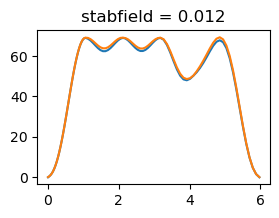

In [79]:
plt.figure(figsize=(3,2))
oms1 = np.array([mfal.NBomega(NBH1, k) for k in kpoi])
plt.plot(xx, oms1[...,1])
plt.plot(xx, oms1[...,0])
plt.title('stabfield = '+str(stf1))

In [80]:
spins2 = [(0,-1.5,0),(0,0,-1.5)]

Nspins1, E1 = mfal.TotEnMinimize(H1, spins2, simple=False)
print(Nspins1)
print(E1)

[[ 1.49299943e-02  2.69222334e-05  1.49992570e+00]
 [ 4.04170499e-05  2.68354176e-11 -1.50000000e+00]]
-73.04445087845276


In [89]:
stab1 = 0.012
SH1 = copy.deepcopy(H1)
Nat = len(SH1.magnetic_atoms)
for i in range(Nat):
    SH1.magnetic_atoms[i].spin_vector = Nspins1[i]
    #SH1.magnetic_atoms[i].spin_vector = (1.5, 0, 0)
NSH1 = mfal.NBhamiltonian(SH1, stabField=stab1)

Text(0.5, 1.0, 'stabfield = 0.012')

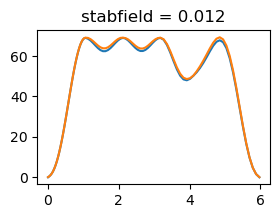

In [90]:
plt.figure(figsize=(3,2))
omsX1 = np.array([mfal.NBomega(NSH1, k) for k in kpoi])
plt.plot(xx, omsX1[...,1])
plt.plot(xx, omsX1[...,0])
plt.title('stabfield = '+str(stab1))